# Credit Card Fraud Detection — Part 1: EDA and Baseline

**Status: in progress.** This notebook covers the first stage of the project: exploring the data,
building a leakage-safe train/test split, and fitting a baseline model that already accounts for class imbalance.

Dataset: [ULB Credit Card Fraud Detection (Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).
Download `creditcard.csv` and place it in `data/`.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, recall_score,
    roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

## 1. Load the data

In [6]:
df = pd.read_csv("../data/creditcard.csv")
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")
df.head()

Shape: (284807, 31)
Missing values: 0
Duplicated rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


The features `V1`–`V28` are anonymised PCA components. Only `Time` (seconds since the first transaction),
`Amount` and the target `Class` (1 = fraud) are in their original form.

## 2. Class imbalance

Class
legit    284315
fraud       492
Name: count, dtype: int64

Fraud rate: 0.173%  (about 1 in 579 transactions)


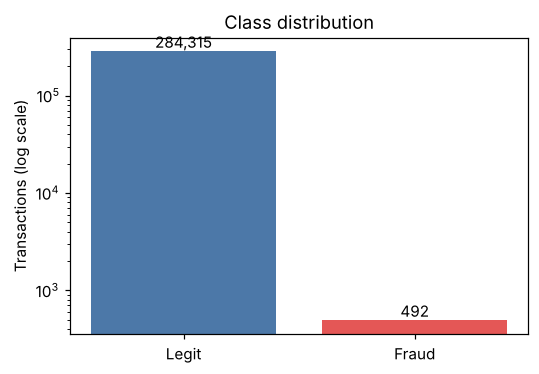

In [ ]:
counts = df["Class"].value_counts().sort_index()
fraud_rate = counts[1] / counts.sum()
print(counts.rename({0: "legit", 1: "fraud"}))
print(f"\nFraud rate: {fraud_rate:.3%}  (about 1 in {int(round(1 / fraud_rate))} transactions)")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Legit", "Fraud"], counts.values, color=["#4c78a8", "#e45756"])
ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../images/class_distribution.png")
plt.show()

### Why accuracy is useless here
A model that always predicts "legit" never catches a single fraud, yet scores almost perfect accuracy.

In [ ]:
y = df["Class"]
X = df.drop(columns="Class")

dummy = DummyClassifier(strategy="most_frequent").fit(X, y)
pred = dummy.predict(X)
print(f"Accuracy : {accuracy_score(y, pred):.4%}")
print(f"Recall   : {recall_score(y, pred):.4f}   <- catches 0% of frauds")

Accuracy : 99.8273%
Recall   : 0.0000   <- catches 0% of frauds


## 3. Quick look at the features

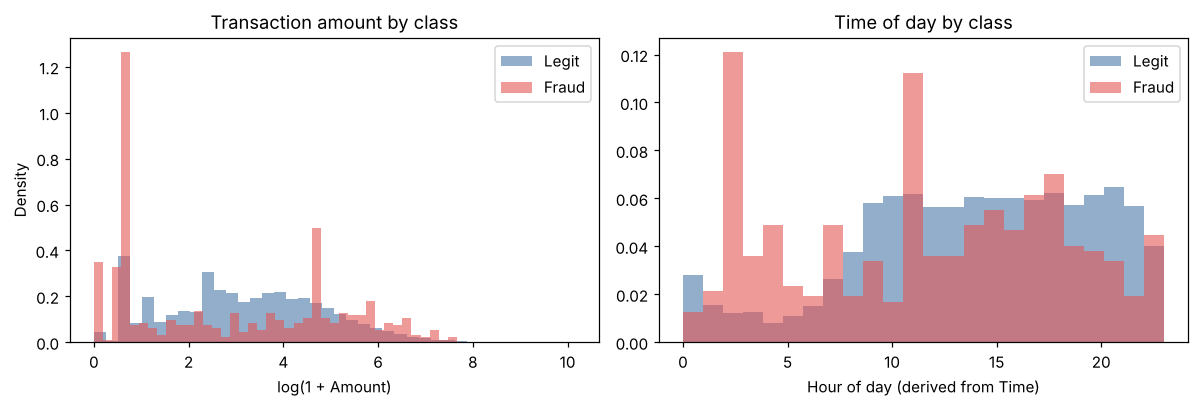

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for label, name, color in [(0, "Legit", "#4c78a8"), (1, "Fraud", "#e45756")]:
    axes[0].hist(np.log1p(df.loc[df.Class == label, "Amount"]), bins=40,
                 alpha=0.6, density=True, label=name, color=color)
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("Transaction amount by class")
axes[0].legend()

hours = (df["Time"] // 3600) % 24
for label, name, color in [(0, "Legit", "#4c78a8"), (1, "Fraud", "#e45756")]:
    axes[1].hist(hours[df.Class == label], bins=24, alpha=0.6, density=True, label=name, color=color)
axes[1].set_xlabel("Hour of day (derived from Time)")
axes[1].set_title("Time of day by class")
axes[1].legend()

plt.tight_layout()
plt.savefig("../images/amount_time_by_class.png")
plt.show()

print(df.groupby("Class")["Amount"].describe().round(2))

In [ ]:
# Which features are most correlated (in absolute value) with the target?
corr = df.drop(columns="Class").corrwith(df["Class"]).abs().sort_values(ascending=False)
corr.head(8).round(3)

V17    0.326
V14    0.303
V12    0.261
V10    0.217
V16    0.197
V3     0.193
V7     0.187
V11    0.155
dtype: float64

## 4. Train/test split
The split happens **before** any resampling or scaling, and is **stratified** so that both sets keep the ~0.17% fraud rate.
The test set stays untouched until final evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows, {y_train.sum()} frauds ({y_train.mean():.3%})")
print(f"Test : {X_test.shape[0]:,} rows, {y_test.sum()} frauds ({y_test.mean():.3%})")

Train: 227,845 rows, 394 frauds (0.173%)
Test : 56,962 rows, 98 frauds (0.172%)


## 5. Baseline: logistic regression with class weights
`class_weight="balanced"` makes errors on the rare class cost more, without changing the data.
Scaling is inside a `Pipeline` so the scaler is fitted on the training data only.

In [ ]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
y_score = baseline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["legit", "fraud"], digits=4))
print(f"ROC-AUC : {roc_auc_score(y_test, y_score):.4f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_score):.4f}   (no-skill baseline = {y_test.mean():.4f})")

              precision    recall  f1-score   support

       legit     0.9999    0.9756    0.9876     56864
       fraud     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962

ROC-AUC : 0.9721
PR-AUC  : 0.7190   (no-skill baseline = 0.0017)


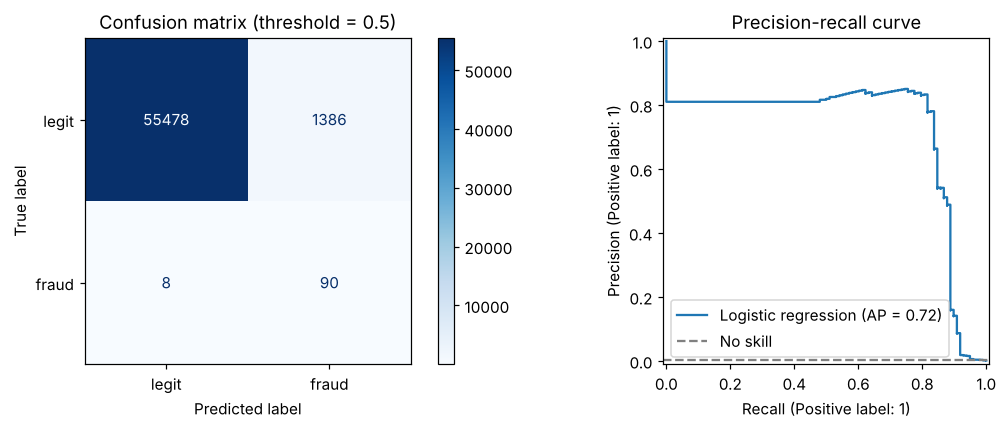

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["legit", "fraud"], cmap="Blues", values_format="d", ax=axes[0]
)
axes[0].set_title("Confusion matrix (threshold = 0.5)")

PrecisionRecallDisplay.from_predictions(y_test, y_score, name="Logistic regression", ax=axes[1])
axes[1].axhline(y_test.mean(), ls="--", color="grey", label="No skill")
axes[1].set_title("Precision-recall curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("../images/baseline_evaluation.png")
plt.show()

## Next steps
- [ ] Tree-based models (random forest, gradient boosting)
- [ ] Resampling (SMOTE / undersampling) inside an `imblearn` Pipeline, applied to training folds only
- [ ] Stratified cross-validation and model comparison
- [ ] Threshold tuning based on the precision/recall trade-off
- [ ] Final evaluation on the held-out test set